# 02 · Exploratory & Business Analysis

This notebook answers the core business questions using the clean tables from notebook 01.

| # | Business question |
|---|---|
| 1 | How are revenue and orders trending, and what drives the peaks? |
| 2 | Which product categories drive revenue, and which disappoint customers? |
| 3 | How reliable is delivery, and how much does it affect customer satisfaction? |
| 4 | Which regions are under-served? |
| 5 | How do customers pay? |
| 6 | How dependent is the marketplace on a few sellers? |
| 7 | When do customers shop? |

All revenue figures are in Brazilian reais (R$) and use **delivered orders** only.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from pathlib import Path

DATA = Path('../data/processed')
IMG = Path('../images')
IMG.mkdir(exist_ok=True)

BLUE, RED, GREY, GREEN = '#2E5EAA', '#D1495B', '#9AA5B1', '#2A9D8F'
sns.set_theme(style='whitegrid', font_scale=1.0)
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold', 'axes.titlesize': 13,
                     'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.float_format', '{:,.2f}'.format)

def save(fig, name):
    fig.savefig(IMG / name, dpi=150, bbox_inches='tight')

reais = mtick.FuncFormatter(lambda x, _: f'R${x/1e6:.1f}M' if x >= 1e6 else ('R$0' if x == 0 else f'R${x/1e3:.0f}K'))

In [2]:
orders = pd.read_csv(DATA / 'fact_orders.csv',
                     parse_dates=['order_purchase_timestamp', 'order_delivered_customer_date',
                                  'order_estimated_delivery_date'])
items = pd.read_csv(DATA / 'fact_order_items.csv', parse_dates=['order_purchase_timestamp'])
orders['is_late'] = orders['is_late'].astype(float)   # True/False/NaN -> 1/0/NaN

delivered = orders[orders['is_delivered']].copy()
delivered_items = items[items['is_delivered']].copy()
print(f'{len(delivered):,} delivered orders, {len(delivered_items):,} items')

96,478 delivered orders, 110,197 items


## Headline KPIs

In [3]:
kpis = pd.Series({
    'Revenue (R$)': delivered['order_value'].sum(),
    'Delivered orders': len(delivered),
    'Unique customers': delivered['customer_unique_id'].nunique(),
    'Average order value (R$)': delivered['order_value'].mean(),
    'Median order value (R$)': delivered['order_value'].median(),
    'Average review score (1-5)': delivered['review_score'].mean(),
    'Avg delivery time (days)': delivered['delivery_days'].mean(),
    'Late delivery rate (%)': delivered['is_late'].mean() * 100,
    'Active sellers': delivered_items['seller_id'].nunique(),
    'Product categories': delivered_items['category'].nunique(),
})
kpis.to_frame('value')

,value
Revenue (R$),"15,419,773.75"
Delivered orders,"96,478.00"
Unique customers,"93,358.00"
Average order value (R$),159.83
Median order value (R$),105.28
Average review score (1-5),4.16
Avg delivery time (days),12.56
Late delivery rate (%),6.77
Active sellers,"2,970.00"
Product categories,74.00


---
## 1. Sales trend

In [4]:
trend = (delivered[delivered['in_trend_window']]
         .groupby('purchase_month')
         .agg(orders=('order_id', 'count'), revenue=('order_value', 'sum'))
         .assign(aov=lambda d: d['revenue'] / d['orders'],
                 mom_growth_pct=lambda d: d['revenue'].pct_change() * 100))
trend

,orders,revenue,aov,mom_growth_pct
purchase_month,,,,
2017-01,750,"127,482.37",169.98,NaN
2017-02,1653,"271,239.32",164.09,112.77
2017-03,2546,"414,330.95",162.74,52.75
2017-04,2303,"390,812.40",169.70,-5.68
2017-05,3546,"566,851.40",159.86,45.04
2017-06,3135,"490,050.37",156.32,-13.55
2017-07,3872,"566,299.08",146.25,15.56
2017-08,4193,"645,832.36",154.03,14.04
2017-09,4150,"701,077.49",168.93,8.55


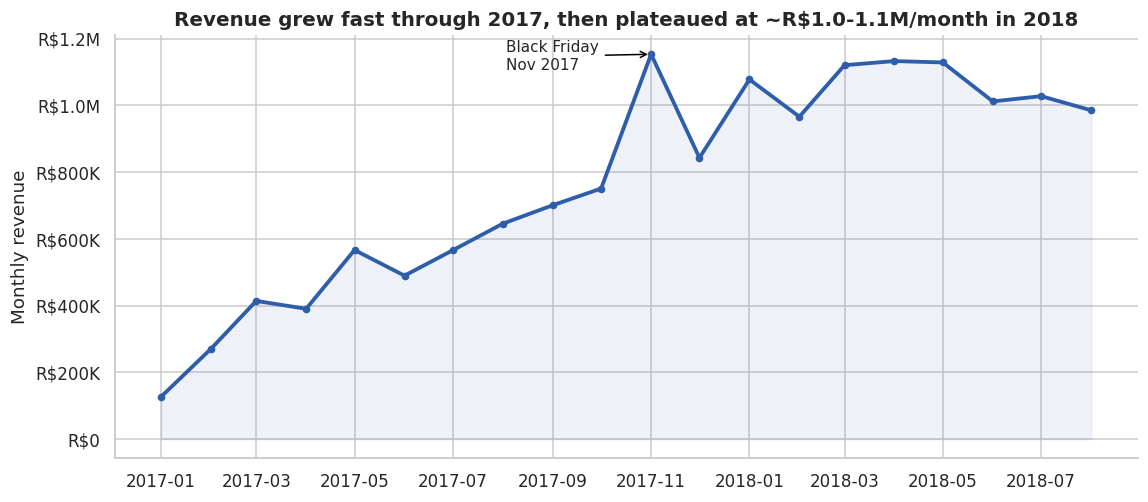

In [5]:
fig, ax = plt.subplots(figsize=(12, 5))
x = pd.to_datetime(trend.index)
ax.plot(x, trend['revenue'], color=BLUE, lw=2.5, marker='o', ms=4)
ax.fill_between(x, trend['revenue'], alpha=0.08, color=BLUE)
ax.yaxis.set_major_formatter(reais)
peak = trend['revenue'].idxmax()
ax.annotate('Black Friday\nNov 2017', xy=(pd.to_datetime(peak), trend.loc[peak, 'revenue']),
            xytext=(-95, -10), textcoords='offset points', fontsize=10,
            arrowprops=dict(arrowstyle='->', color='black'))
ax.set_title('Revenue grew fast through 2017, then plateaued at ~R$1.0-1.1M/month in 2018')
ax.set_ylabel('Monthly revenue'); ax.set_xlabel('')
save(fig, '01_monthly_revenue_trend.png'); plt.show()

In [6]:
ytd_2017 = trend.loc['2017-01':'2017-08', 'revenue'].sum()
ytd_2018 = trend.loc['2018-01':'2018-08', 'revenue'].sum()
print(f'Jan-Aug 2017 revenue: R$ {ytd_2017:,.0f}')
print(f'Jan-Aug 2018 revenue: R$ {ytd_2018:,.0f}')
print(f'Year-over-year growth: {ytd_2018 / ytd_2017 - 1:.1%}')
print(f"Nov 2017 vs Oct 2017 revenue: {trend.loc['2017-11','revenue'] / trend.loc['2017-10','revenue'] - 1:+.1%}")

busiest = delivered.groupby(delivered['order_purchase_timestamp'].dt.date)['order_id'].count().nlargest(5)
print('\nBusiest days (delivered orders):'); print(busiest.to_string())
print(f"Average daily orders in the trend window: {delivered[delivered['in_trend_window']].groupby('purchase_date').size().mean():.0f}")

Jan-Aug 2017 revenue: R$ 3,472,898
Jan-Aug 2018 revenue: R$ 8,451,585
Year-over-year growth: 143.4%
Nov 2017 vs Oct 2017 revenue: +53.6%

Busiest days (delivered orders):
order_purchase_timestamp
2017-11-24    1147
2017-11-25     487
2017-11-27     395
2017-11-26     382
2017-11-28     372
Average daily orders in the trend window: 160


**Findings**
- Revenue for Jan-Aug 2018 was **143% higher** than the same period in 2017.
- Growth flattened during 2018: monthly revenue held around R$1.0-1.1M from January to August.
- **Black Friday (24 Nov 2017)** was the single busiest day with 1,147 delivered orders, roughly 7x a normal day.
  November revenue jumped 54% over October.

---
## 2. Product categories

In [7]:
cat_reviews = (delivered_items[['order_id', 'category']].drop_duplicates()
               .merge(delivered[['order_id', 'review_score', 'delivery_days', 'is_late']], on='order_id'))
categories = (delivered_items.groupby('category')
              .agg(revenue=('item_value', 'sum'), orders=('order_id', 'nunique'),
                   items_sold=('order_item_id', 'count'), avg_price=('price', 'mean'),
                   freight=('freight_value', 'sum'), product_sales=('price', 'sum'))
              .join(cat_reviews.groupby('category')
                    .agg(avg_review=('review_score', 'mean'), avg_delivery_days=('delivery_days', 'mean'),
                         late_rate=('is_late', 'mean')))
              .sort_values('revenue', ascending=False))
categories['revenue_share'] = categories['revenue'] / categories['revenue'].sum()
categories['cumulative_share'] = categories['revenue_share'].cumsum()
categories['freight_to_price'] = categories['freight'] / categories['product_sales']
categories.head(15)[['revenue', 'revenue_share', 'cumulative_share', 'orders', 'avg_price', 'avg_review']]

,revenue,revenue_share,cumulative_share,orders,avg_price,avg_review
category,,,,,,
health_beauty,"1,412,089.53",0.09,0.09,8647,130.28,4.23
watches_gifts,"1,264,333.12",0.08,0.17,5495,199.04,4.12
bed_bath_table,"1,225,209.26",0.08,0.25,9272,93.44,4.00
sports_leisure,"1,118,256.91",0.07,0.33,7530,113.25,4.23
computers_accessories,"1,032,723.77",0.07,0.39,6530,116.26,4.08
furniture_decor,"880,329.92",0.06,0.45,6307,87.25,4.06
housewares,"758,392.25",0.05,0.50,5743,90.60,4.19
cool_stuff,"691,680.89",0.04,0.54,3559,164.12,4.22
auto,"669,454.75",0.04,0.59,3810,139.85,4.15


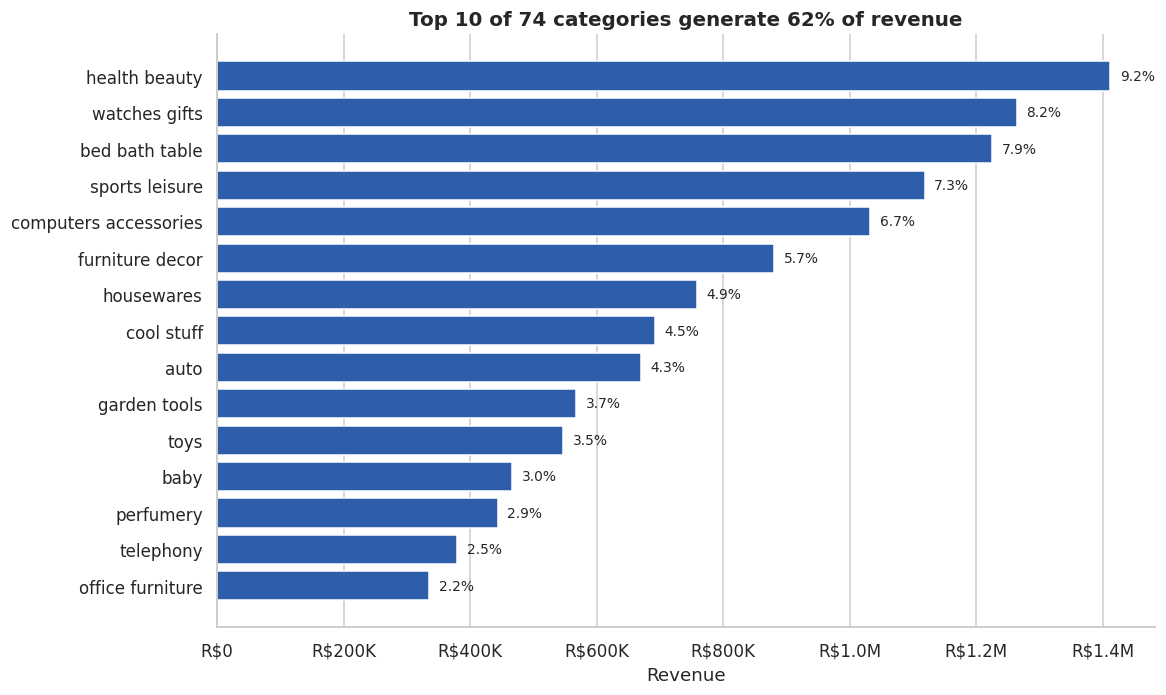

In [8]:
top = categories.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 7))
bars = ax.barh(top.index.str.replace('_', ' '), top['revenue'], color=BLUE)
for b, s in zip(bars, top['revenue_share']):
    ax.text(b.get_width() + 15000, b.get_y() + b.get_height() / 2, f'{s:.1%}', va='center', fontsize=9)
ax.xaxis.set_major_formatter(reais)
ax.set_title(f"Top 10 of {len(categories)} categories generate {categories['revenue_share'].head(10).sum():.0%} of revenue")
ax.set_xlabel('Revenue'); ax.grid(axis='y', visible=False)
save(fig, '02_top_categories_revenue.png'); plt.show()

In [9]:
print(f"Categories needed to reach 50% of revenue: {(categories['cumulative_share'] < 0.5).sum() + 1}")
large = categories[categories['orders'] >= 500].sort_values('avg_review')
print('\nLowest-rated categories (500+ orders):')
large.head(5)[['orders', 'avg_review', 'avg_delivery_days', 'late_rate', 'freight_to_price']]

Categories needed to reach 50% of revenue: 8

Lowest-rated categories (500+ orders):


,orders,avg_review,avg_delivery_days,late_rate,freight_to_price
category,,,,,
office_furniture,1254,3.64,20.64,0.08,0.25
bed_bath_table,9272,4.00,12.99,0.07,0.20
unknown,1392,4.01,12.73,0.07,0.16
telephony,4093,4.05,12.96,0.07,0.22
furniture_decor,6307,4.06,13.07,0.07,0.24


In [10]:
of = cat_reviews[cat_reviews['category'] == 'office_furniture']
overall_on_time = delivered.loc[delivered['is_late'] == 0, 'review_score'].mean()
print(f"Office furniture avg delivery: {of['delivery_days'].mean():.1f} days vs {delivered['delivery_days'].mean():.1f} overall")
print(f"Office furniture freight = {categories.loc['office_furniture','freight_to_price']:.0%} of price "
      f"vs {delivered_items['freight_value'].sum() / delivered_items['price'].sum():.0%} overall")
print(f"Office furniture review when ON TIME: {of.loc[of['is_late'] == 0, 'review_score'].mean():.2f} "
      f"vs {overall_on_time:.2f} for all on-time orders")

Office furniture avg delivery: 20.6 days vs 12.6 overall
Office furniture freight = 25% of price vs 17% overall
Office furniture review when ON TIME: 3.76 vs 4.29 for all on-time orders


**Findings**
- Revenue is concentrated: **8 categories make up half of revenue** and the top 10 make up 62%.
  Health & beauty, watches & gifts, and bed/bath/table lead.
- **Office furniture is the weakest large category (3.64 avg review).** It takes 20.6 days to deliver (vs 12.6 overall)
  and freight is 25% of the product price. Even when delivered on time it scores only 3.76,
  so the problem is not only speed; product or seller quality should be investigated.
- Bed/bath/table is the #3 revenue category but has the second-lowest rating among large categories (4.00).

---
## 3. Delivery performance and customer satisfaction

In [11]:
d = delivered.dropna(subset=['delivery_days']).copy()
print(f"Average delivery time: {d['delivery_days'].mean():.1f} days (median {d['delivery_days'].median():.1f})")
print(f"Delivered late: {d['is_late'].mean():.1%} of orders")
print(f"Average days delivered EARLIER than the estimate: {-d.loc[d['is_late'] == 0, 'delay_days'].mean():.1f}")

d['delay_bucket'] = pd.cut(d['delay_days'], bins=[-np.inf, 0, 3, 7, 14, np.inf],
                           labels=['On time', '1-3 days late', '4-7 days late', '8-14 days late', '15+ days late'])
by_delay = (d.groupby('delay_bucket', observed=True)
            .agg(orders=('order_id', 'count'), avg_review=('review_score', 'mean'),
                 pct_1_2_star=('review_score', lambda s: (s.dropna() <= 2).mean() * 100)))
by_delay

Average delivery time: 12.6 days (median 10.2)
Delivered late: 6.8% of orders
Average days delivered EARLIER than the estimate: 13.5


,orders,avg_review,pct_1_2_star
delay_bucket,,,
On time,89936,4.29,9.27
1-3 days late,1870,3.29,32.13
4-7 days late,1802,2.10,67.68
8-14 days late,1478,1.67,80.15
15+ days late,1384,1.72,78.35


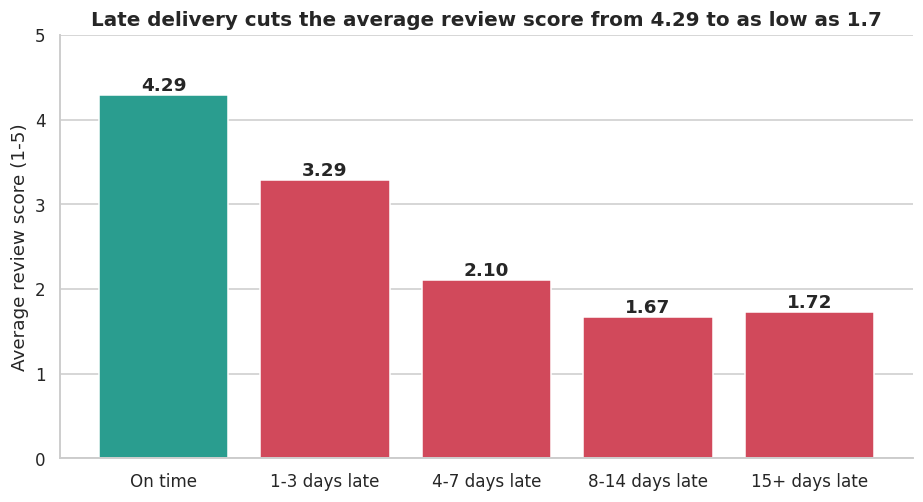

In [12]:
fig, ax = plt.subplots(figsize=(10, 5))
colors = [GREEN] + [RED] * 4
bars = ax.bar(by_delay.index.astype(str), by_delay['avg_review'], color=colors)
for b, v in zip(bars, by_delay['avg_review']):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.05, f'{v:.2f}', ha='center', fontweight='bold')
ax.set_ylim(0, 5); ax.set_ylabel('Average review score (1-5)')
ax.set_title('Late delivery cuts the average review score from 4.29 to as low as 1.7')
ax.grid(axis='x', visible=False)
save(fig, '03_review_score_by_delivery_delay.png'); plt.show()

In [13]:
late_share_of_bad = d.loc[d['review_score'] <= 2, 'is_late'].mean()
print(f"Late orders are {d['is_late'].mean():.1%} of deliveries but {late_share_of_bad:.1%} of all 1-2 star reviews.")
print(f"Correlation between delivery days and review score (order level): {d['delivery_days'].corr(d['review_score']):.2f}")

late_by_month = d[d['in_trend_window']].groupby('purchase_month')['is_late'].mean() * 100
print('\nLate-delivery rate by purchase month (%):'); print(late_by_month.round(1).to_string())

Late orders are 6.8% of deliveries but 32.5% of all 1-2 star reviews.
Correlation between delivery days and review score (order level): -0.33

Late-delivery rate by purchase month (%):
purchase_month
2017-01    2.90
2017-02    3.00
2017-03    4.60
2017-04    6.60
2017-05    3.00
2017-06    3.00
2017-07    2.80
2017-08    2.90
2017-09    4.40
2017-10    4.20
2017-11   12.40
2017-12    7.50
2018-01    5.70
2018-02   14.10
2018-03   19.00
2018-04    4.50
2018-05    6.60
2018-06    1.20
2018-07    3.40
2018-08    6.20


**Findings**
- Olist usually beats its own estimate: average delivery is 12.6 days, and on-time orders arrive about 13 days
  **earlier** than promised. Only 6.8% arrive late.
- But lateness is the strongest driver of bad reviews found in this data. On-time orders average **4.29 stars**;
  orders 4+ days late average about **2 stars**, and 68-80% of them get 1-2 stars.
- **Late orders are 6.8% of deliveries but 32.5% of all 1-2 star reviews.**
- Late rates spiked to 12% in November 2017 (Black Friday volume) and to **14-19% in February-March 2018**,
  showing logistics capacity did not keep up with peak demand.

---
## 4. Regional performance

In [14]:
states = (d.groupby('customer_state')
          .agg(orders=('order_id', 'count'), revenue=('order_value', 'sum'),
               avg_delivery_days=('delivery_days', 'mean'), late_rate=('is_late', 'mean'),
               avg_review=('review_score', 'mean'))
          .sort_values('orders', ascending=False))
states['order_share'] = states['orders'] / states['orders'].sum()
states.head(12)

,orders,revenue,avg_delivery_days,late_rate,avg_review,order_share
customer_state,,,,,,
SP,40494,"5,768,518.23",8.76,0.04,4.25,0.42
RJ,12350,"2,055,401.57",15.31,0.12,3.97,0.13
MG,11354,"1,818,891.67",12.01,0.05,4.19,0.12
RS,5344,"861,278.79",15.30,0.06,4.18,0.06
PR,4923,"781,708.80",11.99,0.04,4.24,0.05
SC,3546,"595,127.78",14.95,0.08,4.13,0.04
BA,3256,"591,137.81",19.34,0.12,3.93,0.03
DF,2080,"346,123.35",12.97,0.06,4.13,0.02
ES,1995,"317,657.93",15.79,0.11,4.08,0.02


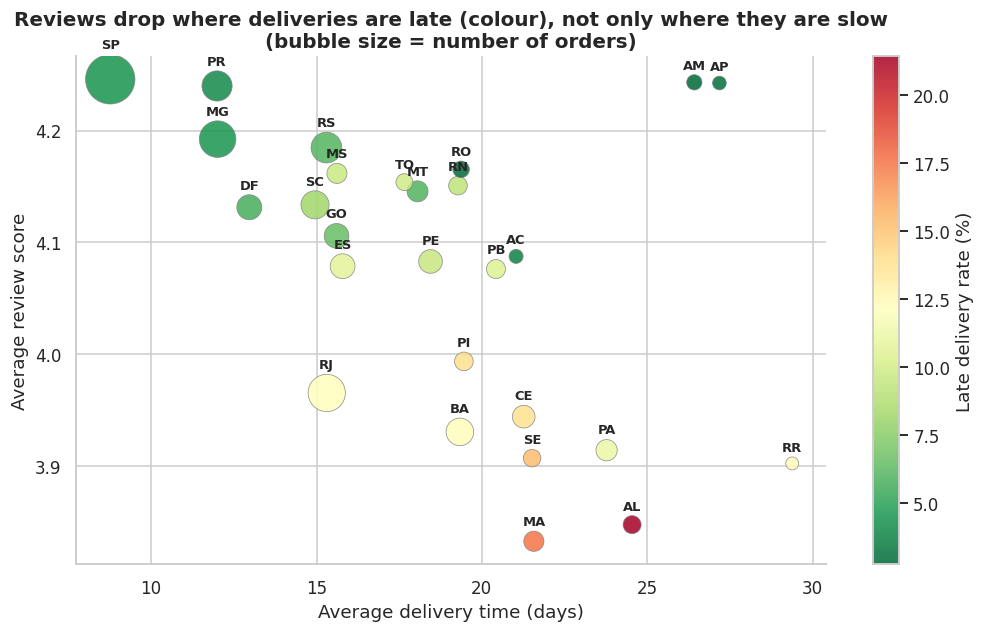

In [15]:
fig, ax = plt.subplots(figsize=(11, 6))
sizes = 40 + np.sqrt(states['orders']) * 5
sc = ax.scatter(states['avg_delivery_days'], states['avg_review'], s=sizes,
                c=states['late_rate'] * 100, cmap='RdYlGn_r', alpha=0.85, edgecolor='grey', lw=0.5)
for (st, r), sz in zip(states.iterrows(), sizes):
    ax.annotate(st, (r['avg_delivery_days'], r['avg_review']), xytext=(0, np.sqrt(sz) / 2 + 4),
                textcoords='offset points', fontsize=8.5, ha='center', fontweight='bold')
cb = plt.colorbar(sc, ax=ax); cb.set_label('Late delivery rate (%)')
ax.set_xlabel('Average delivery time (days)'); ax.set_ylabel('Average review score')
ax.set_title('Reviews drop where deliveries are late (colour), not only where they are slow\n(bubble size = number of orders)')
save(fig, '04_delivery_vs_reviews_by_state.png'); plt.show()

In [16]:
northeast = ['BA', 'PE', 'CE', 'MA', 'PB', 'PI', 'RN', 'AL', 'SE']
north = ['PA', 'AM', 'AC', 'AP', 'RR', 'RO', 'TO']
d['region'] = np.select([d['customer_state'].eq('SP'), d['customer_state'].isin(northeast),
                         d['customer_state'].isin(north)], ['Sao Paulo', 'Northeast', 'North'], 'Other')
region = d.groupby('region').agg(orders=('order_id', 'count'), avg_delivery_days=('delivery_days', 'mean'),
                                 late_rate=('is_late', 'mean'), avg_review=('review_score', 'mean'))
print(f"Correlation between a state's late rate and its avg review: {states['late_rate'].corr(states['avg_review']):.2f}")
print(f"SP + RJ + MG share of orders: {states.loc[['SP','RJ','MG'], 'order_share'].sum():.1%}")
region

Correlation between a state's late rate and its avg review: -0.88
SP + RJ + MG share of orders: 66.5%


,orders,avg_delivery_days,late_rate,avg_review
region,,,,
North,1796,22.59,0.09,4.03
Northeast,9044,20.01,0.13,3.97
Other,45136,14.07,0.08,4.12
Sao Paulo,40494,8.76,0.04,4.25


**Findings**
- Demand is concentrated in the Southeast: **São Paulo alone is 42% of orders**; SP, RJ and MG together are 67%.
- São Paulo customers wait 8.8 days on average. **Northeast customers wait 20 days and are late 12.7% of the time**,
  almost 3x São Paulo's 4.5%.
- Across states, the late-delivery rate is strongly linked to satisfaction (correlation **-0.88**).
  Alagoas (21% late) and Maranhão (17% late) have the lowest reviews. Amazonas and Amapá are the opposite case:
  deliveries take 26-27 days but are rarely late (3%), and reviews stay high. **Customers accept a long wait if the
  promised date is met.**
- **Rio de Janeiro is the biggest problem by volume.** It is the #2 market (13% of orders) and close to São Paulo,
  yet 12.1% of its orders arrive late and its average review (3.97) is among the lowest in the country.

---
## 5. Payment behaviour

In [17]:
pay_mix = delivered['payment_type'].value_counts(normalize=True).mul(100).round(1)
print('Main payment method (% of orders):'); print(pay_mix.to_string())

cc = delivered[delivered['payment_type'] == 'credit_card'].copy()
cc['installment_group'] = pd.cut(cc['payment_installments'], bins=[0, 1, 3, 6, 10, 24],
                                 labels=['1 (full)', '2-3', '4-6', '7-10', '11+'])
inst = cc.groupby('installment_group', observed=True).agg(orders=('order_id', 'count'),
                                                          avg_order_value=('order_value', 'mean'))
print(f"\nCredit-card orders paid in installments: {(cc['payment_installments'] > 1).mean():.1%}")
inst

Main payment method (% of orders):
payment_type
credit_card   75.50
boleto        19.90
voucher        3.10
debit_card     1.50

Credit-card orders paid in installments: 67.9%


,orders,avg_order_value
installment_group,,
1 (full),23358,100.62
2-3,22020,134.96
4-6,15696,181.69
7-10,11422,333.33
11+,329,359.32


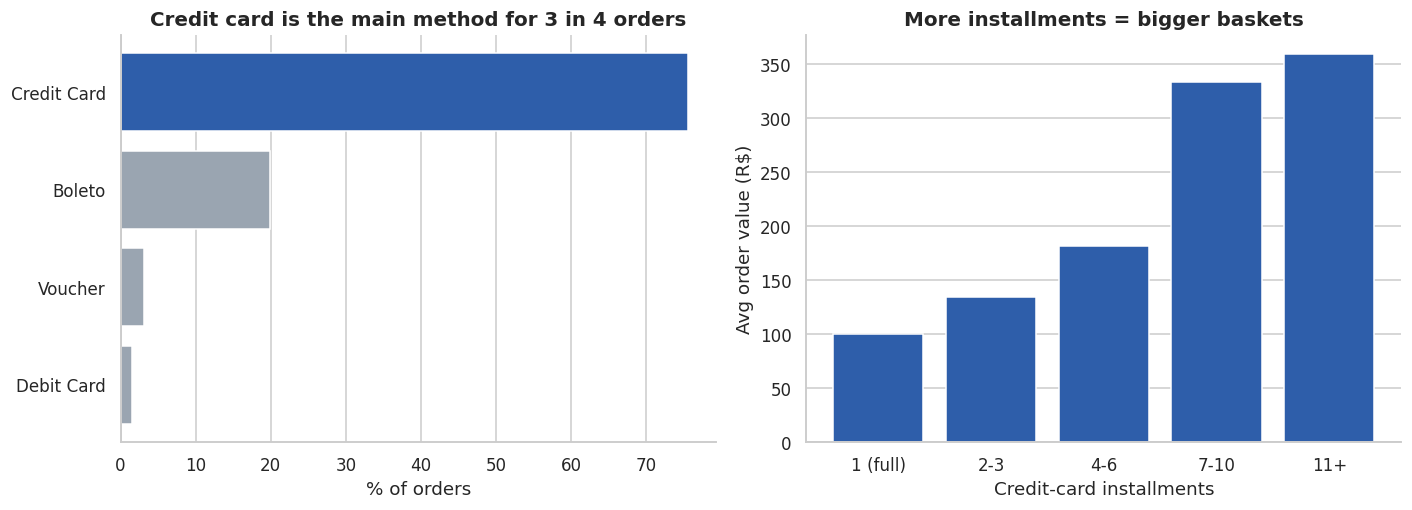

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
pm = pay_mix.sort_values()
axes[0].barh(pm.index.str.replace('_', ' ').str.title(), pm.values, color=[GREY, GREY, GREY, BLUE])
axes[0].set_title('Credit card is the main method for 3 in 4 orders'); axes[0].set_xlabel('% of orders')
axes[0].grid(axis='y', visible=False)
axes[1].bar(inst.index.astype(str), inst['avg_order_value'], color=BLUE)
axes[1].set_title('More installments = bigger baskets'); axes[1].set_xlabel('Credit-card installments')
axes[1].set_ylabel('Avg order value (R$)'); axes[1].grid(axis='x', visible=False)
plt.tight_layout(); save(fig, '05_payment_behaviour.png'); plt.show()

**Findings**
- Credit card is the main payment method for 75.5% of orders, followed by boleto (bank slip) at 19.9%.
- **68% of credit-card orders are paid in installments.** Orders split into 7-10 installments average R$333,
  more than 3x single-payment orders (R$101). Interest-free installments are a key lever for high-ticket categories.

---
## 6. Seller concentration

Sellers: 2,970
Top 10% of sellers generate 66.3% of revenue; top 20% generate 81.6%


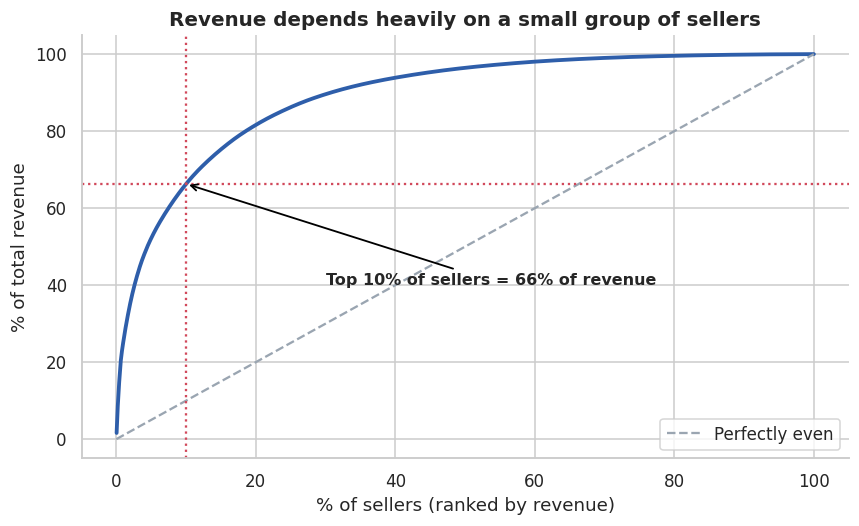

In [19]:
seller_rev = delivered_items.groupby('seller_id')['item_value'].sum().sort_values(ascending=False)
cum_share = seller_rev.cumsum() / seller_rev.sum()
pct_sellers = np.arange(1, len(seller_rev) + 1) / len(seller_rev)
top10 = cum_share.iloc[int(len(seller_rev) * 0.10) - 1]
top20 = cum_share.iloc[int(len(seller_rev) * 0.20) - 1]
print(f'Sellers: {len(seller_rev):,}')
print(f'Top 10% of sellers generate {top10:.1%} of revenue; top 20% generate {top20:.1%}')

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(pct_sellers * 100, cum_share.values * 100, color=BLUE, lw=2.5)
ax.plot([0, 100], [0, 100], ls='--', color=GREY, label='Perfectly even')
ax.axvline(10, color=RED, ls=':', lw=1.5); ax.axhline(top10 * 100, color=RED, ls=':', lw=1.5)
ax.annotate(f'Top 10% of sellers = {top10:.0%} of revenue', xy=(10, top10 * 100), xytext=(30, 40),
            arrowprops=dict(arrowstyle='->', color='black', lw=1.2), fontsize=10.5, fontweight='bold')
ax.set_xlabel('% of sellers (ranked by revenue)'); ax.set_ylabel('% of total revenue')
ax.set_title('Revenue depends heavily on a small group of sellers'); ax.legend(loc='lower right')
save(fig, '06_seller_concentration.png'); plt.show()

**Finding:** about 300 sellers (the top 10%) generate two-thirds of revenue. Losing a few of them would hurt,
so a key-account programme for top sellers is worth considering.

---
## 7. When do customers shop?

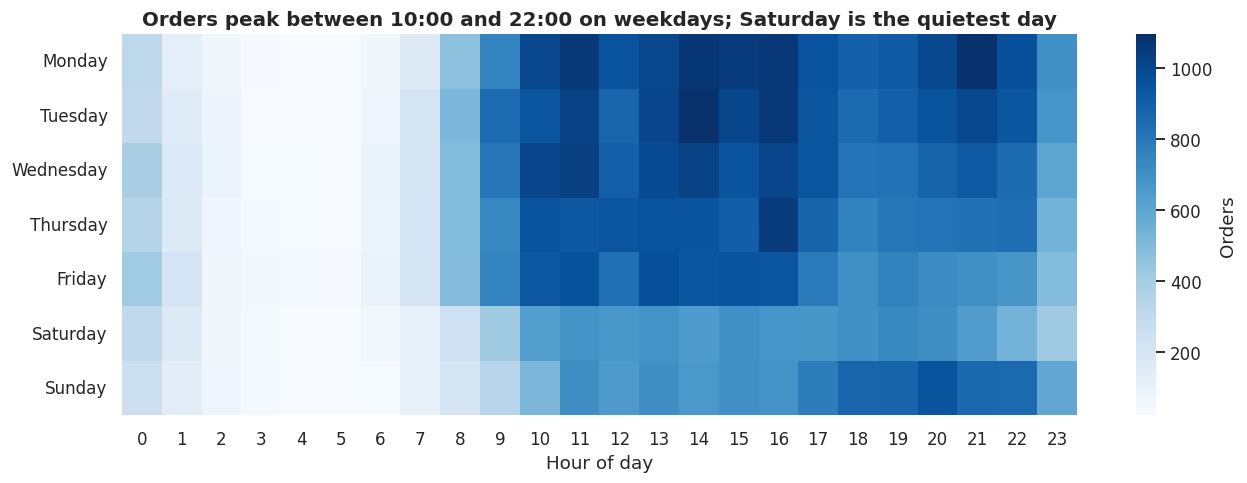

order_purchase_timestamp
Monday      16.30
Tuesday     16.10
Wednesday   15.60
Thursday    14.80
Friday      14.20
Saturday    10.90
Sunday      12.10


In [20]:
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
heat = (delivered.assign(day=delivered['order_purchase_timestamp'].dt.day_name(),
                         hour=delivered['order_purchase_timestamp'].dt.hour)
        .pivot_table(index='day', columns='hour', values='order_id', aggfunc='count')
        .reindex(days_order))

fig, ax = plt.subplots(figsize=(14, 4.5))
sns.heatmap(heat, cmap='Blues', ax=ax, cbar_kws={'label': 'Orders'})
ax.set_title('Orders peak between 10:00 and 22:00 on weekdays; Saturday is the quietest day')
ax.set_xlabel('Hour of day'); ax.set_ylabel('')
save(fig, '07_orders_by_day_and_hour.png'); plt.show()

print(delivered['order_purchase_timestamp'].dt.day_name().value_counts(normalize=True).reindex(days_order).mul(100).round(1).to_string())

**Finding:** Monday and Tuesday are the busiest days (16% of orders each); Saturday is the quietest (11%).
Activity is high from 10:00 to 22:00 and drops overnight. Campaigns and push notifications should target
weekday late mornings and evenings.

---
## Summary of findings

1. **Growth:** Jan-Aug 2018 revenue was up 143% year over year, but monthly revenue flattened during 2018.
2. **Delivery drives satisfaction:** late orders are 6.8% of deliveries but 32.5% of 1-2 star reviews; being 4+ days late
   drops the average review from 4.29 to about 2.
3. **Regional gap:** Northeast customers wait 20 days (vs 8.8 in São Paulo) and are late almost 3x as often.
   Rio de Janeiro, the #2 market, has a 12% late rate.
4. **Category concentration:** 8 of 74 categories make up half of revenue; office furniture is the weakest large category.
5. **Installments matter:** 68% of credit-card orders use installments, and longer plans mean much larger baskets.
6. **Seller dependency:** the top 10% of sellers generate 66% of revenue.

**Next:** `03_customer_analytics_rfm_cohort.ipynb` looks at retention and customer segments.